In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
tracks = pd.read_csv(
    "../data/fma_metadata/tracks.csv",
    index_col=0,
    header=[0, 1, 2]
)

features = pd.read_csv(
    "../data/fma_metadata/features.csv",
    index_col=0,
    header=[0, 1, 2]
)

### Exploring the dataset

In [49]:
print("Tracks:", tracks.shape)
print("Features:", features.shape)

Tracks: (106574, 52)
Features: (106574, 518)


There are 106,574 rows of tracks and 52 columns. This includes track metadata, genre, artist, album, and track info.
There are also 106, 574 rows of features and 518 columns (many different measurements of audio). These are numerical audio features extracted from each track.

In [50]:
print(tracks.columns.tolist()[:30])
print(features.columns.tolist()[:30])

[('album', 'comments', 'Unnamed: 1_level_2'), ('album', 'date_created', 'Unnamed: 2_level_2'), ('album', 'date_released', 'Unnamed: 3_level_2'), ('album', 'engineer', 'Unnamed: 4_level_2'), ('album', 'favorites', 'Unnamed: 5_level_2'), ('album', 'id', 'Unnamed: 6_level_2'), ('album', 'information', 'Unnamed: 7_level_2'), ('album', 'listens', 'Unnamed: 8_level_2'), ('album', 'producer', 'Unnamed: 9_level_2'), ('album', 'tags', 'Unnamed: 10_level_2'), ('album', 'title', 'Unnamed: 11_level_2'), ('album', 'tracks', 'Unnamed: 12_level_2'), ('album', 'type', 'Unnamed: 13_level_2'), ('artist', 'active_year_begin', 'Unnamed: 14_level_2'), ('artist', 'active_year_end', 'Unnamed: 15_level_2'), ('artist', 'associated_labels', 'Unnamed: 16_level_2'), ('artist', 'bio', 'Unnamed: 17_level_2'), ('artist', 'comments', 'Unnamed: 18_level_2'), ('artist', 'date_created', 'Unnamed: 19_level_2'), ('artist', 'favorites', 'Unnamed: 20_level_2'), ('artist', 'id', 'Unnamed: 21_level_2'), ('artist', 'latitude',

- feature columns have three levels like ('chroma_cens', 'max', '04')
    - chroma_cens: feature group
    - max: statistical measurement calculated for that feature
    - 04: feature dimension or the coefficient num

In [51]:
# finding genre column
genre_cols = [
    col for col in tracks.columns
    if "genre_top" in col
]

print(genre_cols)

[('track', 'genre_top', 'Unnamed: 40_level_2')]


In [52]:
# counting tracks in each genre
genre_counts = tracks[genre_cols[0]].value_counts()

print(genre_counts)

(track, genre_top, Unnamed: 40_level_2)
Rock                   14182
Experimental           10608
Electronic              9372
Hip-Hop                 3552
Folk                    2803
Pop                     2332
Instrumental            2079
International           1389
Classical               1230
Jazz                     571
Old-Time / Historic      554
Spoken                   423
Country                  194
Soul-RnB                 175
Blues                    110
Easy Listening            24
Name: count, dtype: int64


#### Checking if the dataset is balanced

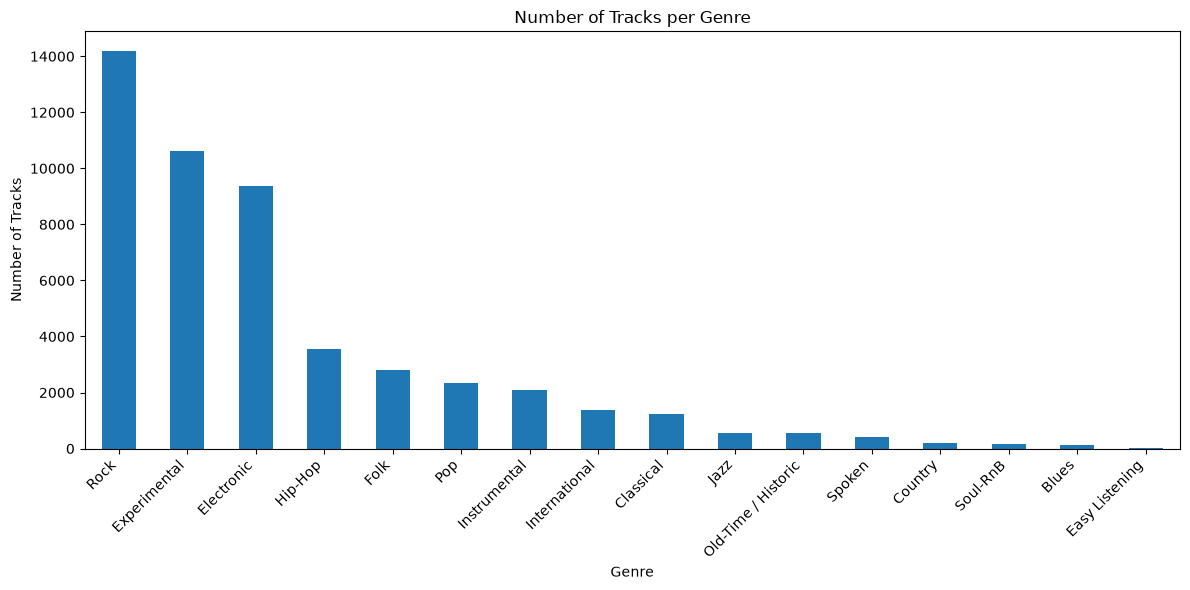

In [53]:
plt.figure(figsize=(12, 6))
genre_counts.plot(kind="bar")

plt.title("Number of Tracks per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- The FMA dataset seems a very imnbalanced because it contains a lot more rock, experimental, and electronic tracks than other genres, 106, 574 tracks across 16 genres
- Rock has 14, 182 tracks while easy listening only has 24
- this is important to note because a model could achieve what seems to be good accuracy but perform poorly on smaller genres, affecting model performance and generalization across genres

In [54]:
feature_groups = features.columns.get_level_values(0).unique()

print(feature_groups)

Index(['chroma_cens', 'chroma_cqt', 'chroma_stft', 'mfcc', 'rmse',
       'spectral_bandwidth', 'spectral_centroid', 'spectral_contrast',
       'spectral_rolloff', 'tonnetz', 'zcr'],
      dtype='str', name='feature')


### Histogram of an audio feature - RMSE

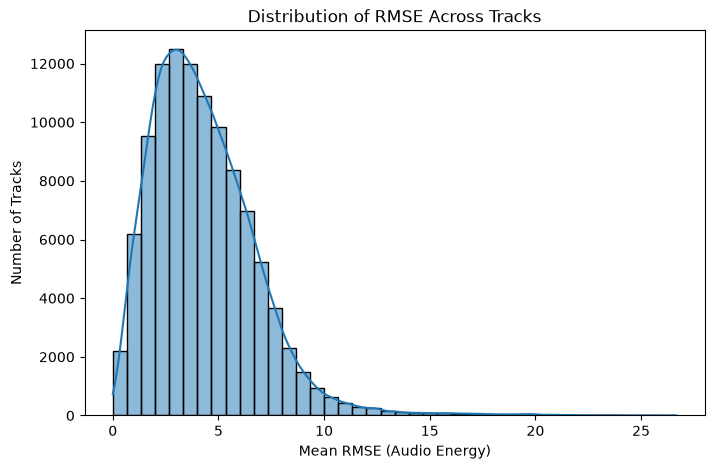

In [55]:
rmse_col = ('rmse', 'mean', '01')

rmse_values = features[rmse_col].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(rmse_values, bins=40, kde=True)

plt.title("Distribution of RMSE Across Tracks")
plt.xlabel("Mean RMSE (Audio Energy)")
plt.ylabel("Number of Tracks")
plt.show()

Histogram observations
- NOTE: RMSE meaures signal energy and not perceived loudness directly
- the distribution is highly right-skewed, with most tracks concentrated between RMSE values of 0 and 10
- few tracks have higher RMSE values, creating a long tail on the right
- this suggests that most tracks have relatively low average signal energy, while a smaller number have substantially higher energy.
For genre classification:
- RMSE may help distinguish tracks with different energy levels, but its usefulness will depend on how much the distributions differ across genres
- since most tracks are concentrated in a relatively narrow range, RMSE alone may not be enough to distinguish genres

In [56]:
#inspect basic stats
print(features.describe())

feature       chroma_cens                                               \
statistics       kurtosis                                                
number                 01             02             03             04   
count       106574.000000  106574.000000  106574.000000  106574.000000   
mean             0.439999       0.199756       0.334683       0.270263   
std             32.285524      11.120903       9.980692      19.074557   
min             -1.955806      -1.936607      -1.967450      -3.000000   
25%             -0.636597      -0.665684      -0.629114      -0.644747   
50%             -0.176557      -0.221131      -0.152708      -0.191032   
75%              0.485000       0.410097       0.529836       0.446800   
max           8843.367188    2864.075195    1777.615967    4257.045898   

feature                                                                 \
statistics                                                               
number                 05            

In [57]:
#checking for missing values
print("Missing values:", features.isna().sum().sum())

Missing values: 0


#### All the stats available for each feature group

In [58]:
for group in feature_groups:
    stats = features[group].columns.get_level_values(0).unique()
    print(group, list(stats))

chroma_cens ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
chroma_cqt ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
chroma_stft ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
mfcc ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
rmse ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
spectral_bandwidth ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
spectral_centroid ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
spectral_contrast ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
spectral_rolloff ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
tonnetz ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']
zcr ['kurtosis', 'max', 'mean', 'median', 'min', 'skew', 'std']


#### Different properties of audio
- Chroma(Chroma CENS): distribution of audio energy across the 12 musical pitch classes, regardless of octave
    - can help capture harmonic and tonal characteristics that could distinguish genres
- MFCC (Mel-Frequency Cepstral Coefficients): represents the short-term spectral shape of audio using a perceptually motivated frequency scale
    - captures timbral characteristics like texture and quality of instruments and vocals
- RMSE (Root Mean Square Energy): measure avg energy or amplitude of an audio signal over time
    - can help distinguish softer and louder musical styles or recordings
- Spectral bandwidth: measures the speed of frequencies around the spectral centroid
    - indicates whether sound energy is concentrated in narrow freq range or spread across a wider range
- Spectral centroid: meausres center of mass of the frequency spectrum; often associated w perceived brightness of audio
    - can help distinguish bright, high-freq sounds from darker, low-freq sounds
- Spectral contrast: meausres differences in energy between spectral peaks and valleys across frequency bands
    - captures differences in harmonic structure and texture
- Spectral rolloff: measures the frequency below which a specified percentage of the total spectral energy is concentrated
    - helps characterize the distribution of low and high-freq energy
- Tonnetz: represents harmonic relationships between pitches using a tonal centroid space
    - captures harmonic relationships and chord-related characteristics
- ZCR (Zero-crossing rate): meausres how frequently the audio waveform crosses the zero-amplitude line
    - can help distinguish noisy, percussive or high-freq sounds from smoother ones


### Comparing features across genres

**Rock vs Classical spectral centroids**

In [59]:
# get spectral centroid
centroid_col = ('spectral_centroid', 'mean', '01')
genre_col = genre_cols[0]

# first verify track IDs are aligned
print(tracks.index.equals(features.index))

True


In [60]:
# get mean col
mean_centroid_cols = [
    col for col in features.columns
    if col[1] == "mean"
]

print(mean_centroid_cols)

[('chroma_cens', 'mean', '01'), ('chroma_cens', 'mean', '02'), ('chroma_cens', 'mean', '03'), ('chroma_cens', 'mean', '04'), ('chroma_cens', 'mean', '05'), ('chroma_cens', 'mean', '06'), ('chroma_cens', 'mean', '07'), ('chroma_cens', 'mean', '08'), ('chroma_cens', 'mean', '09'), ('chroma_cens', 'mean', '10'), ('chroma_cens', 'mean', '11'), ('chroma_cens', 'mean', '12'), ('chroma_cqt', 'mean', '01'), ('chroma_cqt', 'mean', '02'), ('chroma_cqt', 'mean', '03'), ('chroma_cqt', 'mean', '04'), ('chroma_cqt', 'mean', '05'), ('chroma_cqt', 'mean', '06'), ('chroma_cqt', 'mean', '07'), ('chroma_cqt', 'mean', '08'), ('chroma_cqt', 'mean', '09'), ('chroma_cqt', 'mean', '10'), ('chroma_cqt', 'mean', '11'), ('chroma_cqt', 'mean', '12'), ('chroma_stft', 'mean', '01'), ('chroma_stft', 'mean', '02'), ('chroma_stft', 'mean', '03'), ('chroma_stft', 'mean', '04'), ('chroma_stft', 'mean', '05'), ('chroma_stft', 'mean', '06'), ('chroma_stft', 'mean', '07'), ('chroma_stft', 'mean', '08'), ('chroma_stft', 'me

In [61]:
centroid_col = mean_centroid_cols[0]

print("Selected feature:", centroid_col)

Selected feature: ('chroma_cens', 'mean', '01')


In [62]:
# combining genre and feature data
genre_col = genre_cols[0]
comparison = pd.DataFrame({
    "genre": tracks[genre_col],
    "spectral_centroid": features[centroid_col]
})

rock_classical = comparison[
    comparison["genre"].isin(["Rock", "Classical"])
].dropna()

print(rock_classical.groupby("genre")["spectral_centroid"].describe())

             count      mean       std       min       25%       50%  \
genre                                                                  
Classical   1230.0  0.243138  0.065161  0.032664  0.201129  0.243088   
Rock       14182.0  0.252557  0.063399  0.003702  0.213225  0.250925   

                75%       max  
genre                          
Classical  0.284177  0.644795  
Rock       0.289085  0.628921  


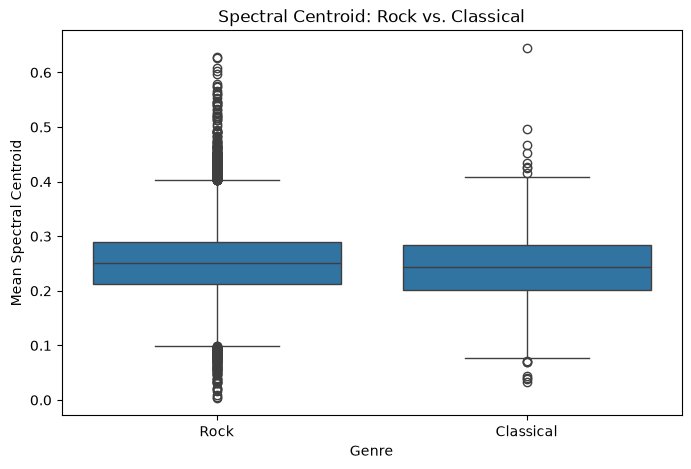

In [63]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=rock_classical,
    x="genre",
    y="spectral_centroid"
)

plt.title("Spectral Centroid: Rock vs. Classical")
plt.xlabel("Genre")
plt.ylabel("Mean Spectral Centroid")
plt.show()

Genre comparison
- compared Rock and Classical
- examined mean spectral centroid, a measure often associated with the brightness of audio
Box plot observations
- the medians are fairly similar, suggesting that the typical spectral centroid is comparable between Rock and Classical
- the box heights (IQRs) are also similar, indicating that the middle 50% of tracks have a comparable spread
- Rock has slightly shorter whiskers, suggesting a smaller range for the non-outlier values
- Rock has more outliers on both the lower and upper ends, suggesting greater variation among some tracks
- the distributions overlap substantially, meaning many Rock and Classical tracks have similar spectral centroid values
What this could mean for genre classification
- spectral centroid alone may not be a strong feature for distinguishing Rock from Classical because their distributions overlap substantially
- however, it could still contribute to classification when combined with other features, such as MFCCs, spectral contrast, or tempo
- this illustrates why examining combinations of audio features may produce better classification results than relying on a single feature